# 06 ? Binary 2D-CNN Training

Model mengklasifikasikan **CHF vs NSR** dari citra DWT empat kanal. Rekaman (bukan segmen) dibagi secara stratified ke train/validation/test agar window yang saling tumpang tindih tidak bocor antar subset. Hasil uji bukan jaminan akurasi klinis.


In [7]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt

current_dir = Path.cwd()
project_candidates = [current_dir, *current_dir.parents]
project_candidates.extend(path for path in current_dir.iterdir() if path.is_dir())
ROOT = next((path.resolve() for path in project_candidates
             if (path / "notebooks").is_dir() and (path / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Folder project ECG_2D_CNN_Project tidak ditemukan.")

WORK_DIR = ROOT / "data" / "processed"
IN_DIR = WORK_DIR / "05_dwt"
OUT_DIR = ROOT / "06_model_chf_nsr"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ["CHF", "NSR"]
RANDOM_STATE = 42
BATCH_SIZE = 64
EPOCHS = 150
LEARNING_RATE = 0.0003
tf.keras.utils.set_random_seed(RANDOM_STATE)


In [8]:
X = np.load(IN_DIR / "X_images.npy").astype(np.float32)
meta = pd.read_csv(IN_DIR / "images_metadata.csv")
if X.ndim != 4 or X.shape[1:] != (28, 28, 4):
    raise ValueError(f"Model mengharapkan citra (N, 28, 28, 4); ditemukan {X.shape}")
if not set(meta["label"]).issubset(set(CLASS_NAMES)):
    raise ValueError(f"Ditemukan label di luar CHF/NSR: {sorted(set(meta['label']) - set(CLASS_NAMES))}")

le = LabelEncoder().fit(CLASS_NAMES)
y = le.transform(meta["label"].to_numpy())
records = meta[["record_id", "label"]].drop_duplicates()
if records["record_id"].duplicated().any():
    raise ValueError("Satu record_id memiliki lebih dari satu label.")
trainval_records, test_records = train_test_split(
    records, test_size=0.15, stratify=records["label"], random_state=RANDOM_STATE
)
train_records, val_records = train_test_split(
    trainval_records, test_size=0.17647, stratify=trainval_records["label"],
    random_state=RANDOM_STATE + 1
)

def indices_for(record_table):
    return np.flatnonzero(meta["record_id"].isin(record_table["record_id"]).to_numpy())

train_idx = indices_for(train_records)
val_idx = indices_for(val_records)
test_idx = indices_for(test_records)
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

record_sets = [set(meta.iloc[idx]["record_id"]) for idx in (train_idx, val_idx, test_idx)]
if (record_sets[0] & record_sets[1]) or (record_sets[0] & record_sets[2]) or (record_sets[1] & record_sets[2]):
    raise AssertionError("record_id ditemukan pada lebih dari satu subset.")
print("Class order:", list(le.classes_))
for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    print(name, len(idx), "segments | records:", meta.iloc[idx]["record_id"].nunique(),
          "| records per class:", meta.iloc[idx][["record_id", "label"]].drop_duplicates()["label"].value_counts().to_dict())
with (OUT_DIR / "label_encoder.pkl").open("wb") as file:
    pickle.dump(le, file)


Class order: [np.str_('CHF'), np.str_('NSR')]
train 3680 segments | records: 46 | records per class: {'NSR': 25, 'CHF': 21}
validation 800 segments | records: 10 | records per class: {'NSR': 6, 'CHF': 4}
test 800 segments | records: 10 | records per class: {'CHF': 5, 'NSR': 5}


In [9]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(28, 28, 4)),
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(96, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu",
                 kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
    layers.Dropout(0.35),
    layers.Dense(len(le.classes_), activation="softmax")
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 96)       │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 96)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,986 (320.26 KB)

 Trainable params: 81,602 (318.76 KB)

 Non-trainable params: 384 (1.50 KB)

In [10]:
class_weights_array = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
class_weights = dict(zip(np.unique(y_train), class_weights_array))
print("Class weights:", {le.classes_[int(k)]: round(float(v), 3) for k, v in class_weights.items()})

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(OUT_DIR / "best_model.keras",
                                       monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=7, min_delta=1e-4,
                                         min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                     min_delta=1e-4, restore_best_weights=True)
]
history = model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks,
    class_weight=class_weights, verbose=1
)
model.save(OUT_DIR / "final_model.keras")
with (OUT_DIR / "training_history.pkl").open("wb") as file:
    pickle.dump(history.history, file)
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print(f"Epoch terbaik berdasarkan validation loss: {best_epoch}")


Class weights: {np.str_('CHF'): 1.095, np.str_('NSR'): 0.92}
Epoch 1/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 8s 82ms/step - accuracy: 0.7269 - loss: 0.5302 - val_accuracy: 0.6000 - val_loss: 0.6440 - learning_rate: 3.0000e-04
Epoch 2/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.8690 - loss: 0.3350 - val_accuracy: 0.5750 - val_loss: 0.6371 - learning_rate: 3.0000e-04
Epoch 3/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9266 - loss: 0.2180 - val_accuracy: 0.6438 - val_loss: 0.6227 - learning_rate: 3.0000e-04
Epoch 4/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9405 - loss: 0.1711 - val_accuracy: 0.6363 - val_loss: 0.7315 - learning_rate: 3.0000e-04
Epoch 5/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.9478 - loss: 0.1450 - val_accuracy: 0.5888 - val_loss: 0.9936 - learning_rate: 3.0000e-04
Epoch 6/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9573 - loss: 0.1178 - val_accuracy: 0.5863 - val_loss: 1.4274 - learning_rate: 3.0000e-04
Epo

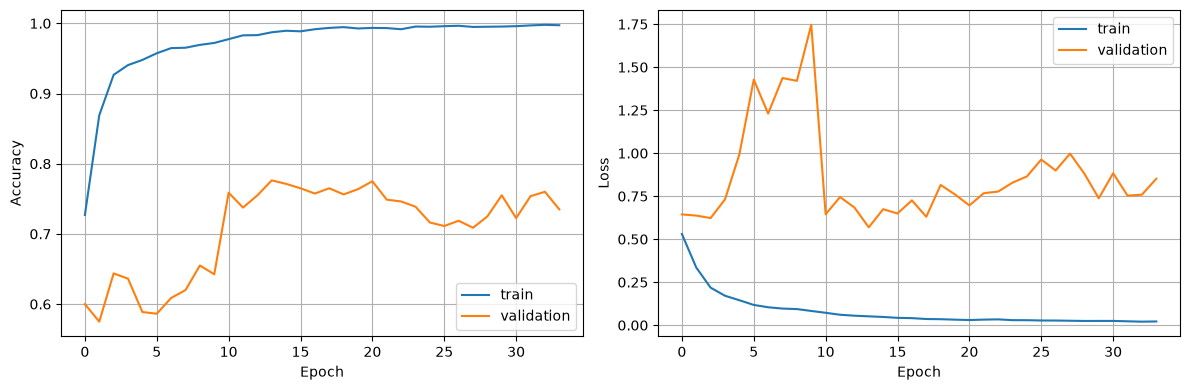

In [11]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Model dan encoder biner tersimpan terpisah di `06_model_chf_nsr/`, sehingga artefak lama tiga kelas tidak dapat ikut tercampur. Notebook 07 menghitung metrik segment-level dan record-level pada test set yang sama.
